 # 04 Baseline Models

Train and evaluate baseline toxicity classification models.

This notebook includes:

- Rule-based sensitive word detector
- TF-IDF + Multinomial Logistic Regression

The text-only model uses only the current chat message and does not use contextual features.


## 1. Load Labeled Dataset

读取 `03_labeling.ipynb` 生成的 1200 条三分类数据。

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_ROOT = Path(
    r"D:\JupyterProject\AIML339_Toxicity"
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "labeled_context_1200.parquet"
)

df = pd.read_parquet(DATA_PATH)

print("Dataset shape:")
print(df.shape)

print("\nLabel distribution:")
print(
    df["label"]
    .value_counts()
    .sort_index()
)

display(df.head())

Dataset shape:
(1200, 26)

Label distribution:
label
0    396
1    462
2    342
Name: count, dtype: int64


,match_id,time,player_slot,key,prev_message_1,prev_message_2,prev_message_3,prev_message_4,prev_message_5,gold,...,seconds_since_teamfight,recent_teamfight_120s,recent_teamfight_loss_120s,chat_context,emotional_candidate,harmful_candidate,sampling_group,annotation_id,label,notes
0,24301,1060,2,man ur life must be shit,dumbass,Gg wp,u need the points more than me,if u didnt suck so much we coudla played a game,retard,10280,...,NaN,0,0,retard | if u didnt suck so much we coudla pla...,False,True,harmful_candidate,1,2,None
1,49193,2180,131,dont know why,fuck me,fuck valve,relax,we will,steo by step,13984,...,58.0,1,1,steo by step | we will | relax | fuck valve | ...,True,False,emotional_candidate,2,0,None
2,4367,2072,132,can u end,lina,3k,can u throne im not defending now,throne it pls,im sure he proved to be a real challenge mid k...,13532,...,107.0,1,1,im sure he proved to be a real challenge mid k...,False,False,random,3,0,None
3,1909,2191,129,noob jugger,wa u utli for me,5555,55.,account buyer,how did you get those mmr storm,17479,...,54.0,1,0,how did you get those mmr storm | account buye...,False,True,harmful_candidate,4,2,None
4,16069,1889,3,it is not about how bad he is,he won,i tried to win he tried to lose,dp won,hehe,win lol,18559,...,49.0,1,0,win lol | hehe | dp won | i tried to win he tr...,True,False,emotional_candidate,5,1,None


## 2. Select Baseline Data

只保留当前聊天文本、比赛 ID 和标签。

Baseline 模型不会使用聊天历史、行为特征或比赛状态。

In [2]:
baseline_data = df[
    [
        "match_id",
        "key",
        "label"
    ]
].copy()

baseline_data["key"] = (
    baseline_data["key"]
    .fillna("")
    .astype(str)
)

baseline_data["label"] = (
    baseline_data["label"]
    .astype(int)
)

print("Rows:")
print(len(baseline_data))

print("\nMissing messages:")
print(
    baseline_data["key"]
    .isna()
    .sum()
)

display(
    baseline_data.head(10)
)

Rows:
1200

Missing messages:
0


,match_id,key,label
0,24301,man ur life must be shit,2
1,49193,dont know why,0
2,4367,can u end,0
3,1909,noob jugger,2
4,16069,it is not about how bad he is,1
5,31390,bara,0
6,34912,yes storm was bad,1
7,3381,noob am,2
8,7618,wtf is that,1
9,40321,sorry jugg,0


## 3. Split Train, Validation and Test Sets

按照 match ID 划分训练集、验证集和测试集，避免同一场比赛中的聊天消息出现在不同数据集造成数据泄漏。

目标比例约为：

- 70% Training
- 15% Validation
- 15% Test

In [3]:
from sklearn.model_selection import GroupShuffleSplit

groups = baseline_data["match_id"]

first_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=339
)

train_idx, temp_idx = next(
    first_split.split(
        baseline_data,
        groups=groups
    )
)

train_data = (
    baseline_data
    .iloc[train_idx]
    .copy()
)

temp_data = (
    baseline_data
    .iloc[temp_idx]
    .copy()
)

In [4]:
second_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=339
)

val_idx, test_idx = next(
    second_split.split(
        temp_data,
        groups=temp_data["match_id"]
    )
)

val_data = (
    temp_data
    .iloc[val_idx]
    .copy()
)

test_data = (
    temp_data
    .iloc[test_idx]
    .copy()
)

print("Train:")
print(len(train_data))

print("\nValidation:")
print(len(val_data))

print("\nTest:")
print(len(test_data))

Train:
838

Validation:
183

Test:
179


## 4. Check Data Split

检查训练集、验证集和测试集的标签分布，并确认三个数据集之间没有重复的 match ID。

In [5]:
def show_distribution(name, data):
    counts = (
        data["label"]
        .value_counts()
        .sort_index()
    )

    percentages = (
        data["label"]
        .value_counts(normalize=True)
        .sort_index()
        * 100
    )

    result = pd.DataFrame({
        "count": counts,
        "percentage": percentages.round(2)
    })

    print(name)
    display(result)


show_distribution(
    "Training Set",
    train_data
)

show_distribution(
    "Validation Set",
    val_data
)

show_distribution(
    "Test Set",
    test_data
)

Training Set


,count,percentage
label,,
0,281,33.53
1,313,37.35
2,244,29.12


Validation Set


,count,percentage
label,,
0,59,32.24
1,76,41.53
2,48,26.23


Test Set


,count,percentage
label,,
0,56,31.28
1,73,40.78
2,50,27.93


In [6]:
train_matches = set(
    train_data["match_id"]
)

val_matches = set(
    val_data["match_id"]
)

test_matches = set(
    test_data["match_id"]
)

print(
    "Train / Validation overlap:",
    len(train_matches & val_matches)
)

print(
    "Train / Test overlap:",
    len(train_matches & test_matches)
)

print(
    "Validation / Test overlap:",
    len(val_matches & test_matches)
)

Train / Validation overlap: 0
Train / Test overlap: 0
Validation / Test overlap: 0


## 5. Define Sensitive Word Lists

建立简单的分级敏感词规则。

严重辱骂、威胁和直接攻击被划分为 Harmful；一般脏话和负面情绪表达被划分为 Limited Emotional。

In [7]:
import re

harmful_patterns = [
    r"\bfuck you\b",
    r"\bfuck u\b",
    r"\bkys\b",
    r"\bkill yourself\b",
    r"\bretard\b",
    r"\bretarded\b",
    r"\bidiot\b",
    r"\bstupid\b",
    r"\btrash\b",
    r"\bnoob\b",
    r"\bcunt\b",
    r"\bfaggot\b",
    r"\bnigger\b",
    r"\bnigga\b",
    r"\buninstall\b"
]

emotional_patterns = [
    r"\bwtf\b",
    r"\bfuck\b",
    r"\bshit\b",
    r"\bdamn\b",
    r"\bsad\b",
    r"\bbad\b",
    r"\blost\b",
    r"\blose\b",
    r"\bthrow\b",
    r"\bthrowing\b",
    r"\breport\b",
    r"\bez\b",
    r"\beasy\b"
]

print(
    "Harmful patterns:",
    len(harmful_patterns)
)

print(
    "Emotional patterns:",
    len(emotional_patterns)
)

Harmful patterns: 15
Emotional patterns: 13


## 6. Build Rule-Based Detector

根据敏感词规则预测三分类标签。

模型首先检查 Harmful 规则，然后检查 Limited Emotional 规则；如果都没有匹配，则预测为 Normal。

In [8]:
def sensitive_word_detector(message):
    text = str(message).lower()

    for pattern in harmful_patterns:
        if re.search(pattern, text):
            return 2

    for pattern in emotional_patterns:
        if re.search(pattern, text):
            return 1

    return 0

In [9]:
test_messages = [
    "group mid",
    "wtf",
    "this is bad",
    "fuck you",
    "you are trash",
    "nice game"
]

for message in test_messages:
    prediction = sensitive_word_detector(
        message
    )

    print(
        prediction,
        message
    )

0 group mid
1 wtf
1 this is bad
2 fuck you
2 you are trash
0 nice game


## 7. Evaluate Rule-Based Baseline

在 validation set 上测试敏感词规则模型，并计算三分类 Precision、Recall、F1 和 Macro-F1。

In [10]:
from sklearn.metrics import (
    classification_report,
    f1_score
)

val_rule_predictions = (
    val_data["key"]
    .apply(
        sensitive_word_detector
    )
)

print("Macro F1:")
print(
    f1_score(
        val_data["label"],
        val_rule_predictions,
        average="macro"
    )
)

print("\nClassification Report:")

print(
    classification_report(
        val_data["label"],
        val_rule_predictions,
        target_names=[
            "Normal",
            "Limited Emotional",
            "Harmful"
        ],
        digits=3
    )
)

Macro F1:
0.83636648532252

Classification Report:
                   precision    recall  f1-score   support

           Normal      0.744     0.983     0.847        59
Limited Emotional      0.881     0.776     0.825        76
          Harmful      0.947     0.750     0.837        48

         accuracy                          0.836       183
        macro avg      0.857     0.836     0.836       183
     weighted avg      0.854     0.836     0.835       183



## 8. Check Rule-Based Predictions

检查规则模型预测的类别分布，了解模型是否明显偏向某一类别。

In [11]:
rule_prediction_counts = (
    val_rule_predictions
    .value_counts()
    .sort_index()
)

print(
    rule_prediction_counts
)

key
0    78
1    67
2    38
Name: count, dtype: int64


## 9. Create TF-IDF Features

使用 TF-IDF 将当前聊天消息转换为数值特征。

这里只使用当前消息文本，不使用聊天历史或其他上下文信息。

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_features=5000,
    sublinear_tf=True
)

X_train = tfidf.fit_transform(
    train_data["key"]
)

X_val = tfidf.transform(
    val_data["key"]
)

y_train = train_data["label"]
y_val = val_data["label"]

print("Training TF-IDF shape:")
print(X_train.shape)

print("\nValidation TF-IDF shape:")
print(X_val.shape)

print("\nVocabulary size:")
print(len(tfidf.vocabulary_))

Training TF-IDF shape:
(838, 397)

Validation TF-IDF shape:
(183, 397)

Vocabulary size:
397


## 10. Train Logistic Regression

使用 TF-IDF 特征训练三分类 Logistic Regression 模型。

In [14]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=339
)

logistic_model.fit(
    X_train,
    y_train
)

print("Model training complete.")

Model training complete.


## 11. Evaluate Text-Only Baseline

在 validation set 上评估 TF-IDF + Logistic Regression，并计算三分类 Precision、Recall、F1 和 Macro-F1。

In [15]:
val_logistic_predictions = (
    logistic_model.predict(
        X_val
    )
)

logistic_macro_f1 = f1_score(
    y_val,
    val_logistic_predictions,
    average="macro"
)

print("Macro F1:")
print(logistic_macro_f1)

print("\nClassification Report:")

print(
    classification_report(
        y_val,
        val_logistic_predictions,
        target_names=[
            "Normal",
            "Limited Emotional",
            "Harmful"
        ],
        digits=3
    )
)

Macro F1:
0.8212560386473431

Classification Report:
                   precision    recall  f1-score   support

           Normal      0.753     0.932     0.833        59
Limited Emotional      0.887     0.724     0.797        76
          Harmful      0.833     0.833     0.833        48

         accuracy                          0.820       183
        macro avg      0.825     0.830     0.821       183
     weighted avg      0.830     0.820     0.818       183



## 12. Compare Baseline Models

比较规则模型和纯文本 Logistic Regression 在 validation set 上的 Macro-F1。

In [16]:
rule_macro_f1 = f1_score(
    val_data["label"],
    val_rule_predictions,
    average="macro"
)

comparison = pd.DataFrame({
    "Model": [
        "Rule-Based Detector",
        "TF-IDF + Logistic Regression"
    ],
    "Macro F1": [
        rule_macro_f1,
        logistic_macro_f1
    ]
})

display(comparison)

,Model,Macro F1
0,Rule-Based Detector,0.836366
1,TF-IDF + Logistic Regression,0.821256


## 13. Check Text Model Predictions

检查文本模型预测的类别数量，判断模型是否明显偏向某一个类别。

In [17]:
logistic_prediction_counts = (
    pd.Series(
        val_logistic_predictions
    )
    .value_counts()
    .sort_index()
)

print(
    logistic_prediction_counts
)

0    73
1    62
2    48
Name: count, dtype: int64


## 14. Confusion Matrix

使用 confusion matrix 查看 TF-IDF + Logistic Regression 最容易混淆的类别。

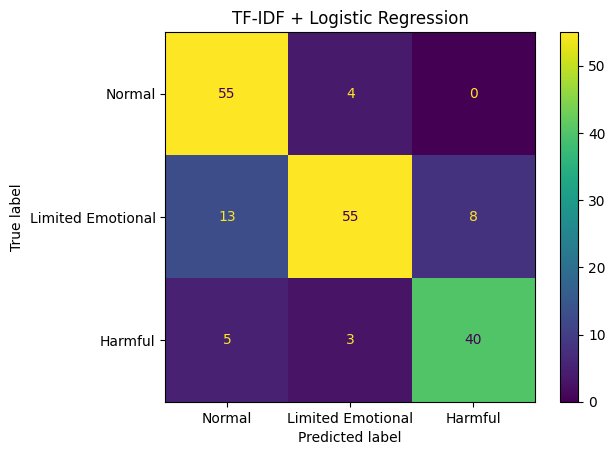

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_val,
    val_logistic_predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Normal",
        "Limited Emotional",
        "Harmful"
    ]
)

disp.plot()

plt.title(
    "TF-IDF + Logistic Regression"
)

plt.show()

## 15. Inspect Misclassified Messages

查看 validation set 中分类错误的消息，帮助分析模型在哪些类型的文本上容易出错。

In [19]:
error_analysis = val_data[
    [
        "key",
        "label"
    ]
].copy()

error_analysis[
    "prediction"
] = val_logistic_predictions

errors = error_analysis[
    error_analysis["label"]
    != error_analysis["prediction"]
].copy()

print("Misclassified messages:")
print(len(errors))

display(
    errors.head(30)
)

Misclassified messages:
33


,key,label,prediction
16,Пошел к мамке,1,0
23,look at our retarded pick,2,0
28,fuck,1,2
58,gg tide never ult,1,0
67,eto chmo u menya v mute eshe s proshloi igri,2,0
126,talk trash r bro?.,1,2
204,turns out this hero is still stupid,1,2
224,rs me,0,1
270,ALL TİME GANK MİD ?,1,0
274,this is fucking infuriating,1,2


## 16. Save Data Split

保存每条标注数据所属的训练集、验证集或测试集。

后续 Context Model 将使用完全相同的数据划分，保证模型之间的比较公平。

In [20]:
split_data = df[
    [
        "annotation_id",
        "match_id"
    ]
].copy()

train_match_ids = set(
    train_data["match_id"]
)

val_match_ids = set(
    val_data["match_id"]
)

test_match_ids = set(
    test_data["match_id"]
)

def assign_split(match_id):
    if match_id in train_match_ids:
        return "train"

    if match_id in val_match_ids:
        return "validation"

    if match_id in test_match_ids:
        return "test"

    return "unknown"


split_data["split"] = (
    split_data["match_id"]
    .apply(assign_split)
)

print(
    split_data["split"]
    .value_counts()
)

split
train         838
validation    183
test          179
Name: count, dtype: int64


## 17. Save Data Split File

保存固定的数据划分，供 Context Model 和最终 Evaluation 使用。

In [21]:
SPLIT_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "dataset_split.parquet"
)

split_data.to_parquet(
    SPLIT_PATH,
    index=False
)

print("Saved to:")
print(SPLIT_PATH)

Saved to:
D:\JupyterProject\AIML339_Toxicity\data\processed\dataset_split.parquet


## 18. Save Text Baseline Model

保存 TF-IDF vectorizer 和 Logistic Regression 模型，供最终模型比较和测试使用。

In [22]:
import joblib

MODEL_DIR = (
    PROJECT_ROOT
    / "models"
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TFIDF_PATH = (
    MODEL_DIR
    / "baseline_tfidf.joblib"
)

LOGISTIC_PATH = (
    MODEL_DIR
    / "baseline_logistic.joblib"
)

joblib.dump(
    tfidf,
    TFIDF_PATH
)

joblib.dump(
    logistic_model,
    LOGISTIC_PATH
)

print("Saved TF-IDF:")
print(TFIDF_PATH)

print("\nSaved Logistic Regression:")
print(LOGISTIC_PATH)

Saved TF-IDF:
D:\JupyterProject\AIML339_Toxicity\models\baseline_tfidf.joblib

Saved Logistic Regression:
D:\JupyterProject\AIML339_Toxicity\models\baseline_logistic.joblib


## 19. Save Validation Predictions

保存两个 baseline 模型在 validation set 上的预测结果，供后续分析和模型比较使用。

In [23]:
validation_results = val_data[
    [
        "match_id",
        "key",
        "label"
    ]
].copy()

validation_results[
    "rule_prediction"
] = val_rule_predictions.values

validation_results[
    "logistic_prediction"
] = val_logistic_predictions

VALIDATION_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "baseline_validation_predictions.parquet"
)

validation_results.to_parquet(
    VALIDATION_PATH,
    index=False
)

print("Saved to:")
print(VALIDATION_PATH)

print("\nRows:")
print(len(validation_results))

Saved to:
D:\JupyterProject\AIML339_Toxicity\data\processed\baseline_validation_predictions.parquet

Rows:
183
